# Support Vector Machines for Digit Recognition

**Author:** Mohammed Alaa Eddine GUERBOUZ  
**University:** University of Ghardaia — Department of Mathematics and Computer Science  
**Academic period:** Master 2 SIEC · 2024–2025  
**Type:** Original university coursework, reorganized for a GitHub portfolio in 2026

**Problem:** Classify handwritten digits using traditional machine learning.

**Approach:** SVM and standard train/test split using scikit-learn datasets.

> Historical coursework: the computational cells below are retained from the original submission. Results have not been independently rerun or revalidated as part of the portfolio reorganization. See this folder's README for data and execution notes.


---

<div class="alert alert-success">

<center><b>University of Ghardaia</b></center>
    
<center><i>Faculty of Science and Technology - Department of Mathematics and Computer Science – Master 2 SIEC - 2024/2025</i>
</center></div>

------

<br><br>

<center>
<span style='font-weight:bold;font-size:27px;'><span style='color:#5D00FF;'>TP 3 exo 2 </span>
    </span>
    </center>
<br>


### GUERBOUZ MOHAMMED ALAA EDDINE

### Step 1: Load Required Libraries and Dataset



In [1]:
# Import necessary libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn import svm, datasets
from sklearn.model_selection import train_test_split


### Step 2: Load and Preprocess the Digits Dataset


In [2]:
# Load the Digits dataset
from sklearn.datasets import load_digits
digits = load_digits()

# Extract data and target
X, y = digits.data, digits.target
print(f"Dataset shape: X={X.shape}, y={y.shape}")

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


Dataset shape: X=(1797, 64), y=(1797,)


### Step 3: Train and Evaluate Linear SVM


In [3]:
# Train a Linear SVM
C = 1.0  # Regularization parameter
lin_svc = svm.LinearSVC(C=C, random_state=42)
lin_svc.fit(X_train, y_train)

# Evaluate the Linear SVM
score = lin_svc.score(X_test, y_test)
print(f"Linear SVM Test Accuracy: {score:.2f}")


Linear SVM Test Accuracy: 0.95


### Step 4: Train and Evaluate Gaussian Kernel SVM


In [4]:
# Train an SVM with Gaussian (RBF) kernel
gamma_values = ['scale', 'auto', 0.01, 0.1, 1]
results = {}

for gamma in gamma_values:
    rbf_svc = svm.SVC(kernel='rbf', C=C, gamma=gamma, random_state=42)
    rbf_svc.fit(X_train, y_train)
    score = rbf_svc.score(X_test, y_test)
    results[gamma] = score
    print(f"RBF SVM Test Accuracy with gamma={gamma}: {score:.2f}")


RBF SVM Test Accuracy with gamma=scale: 0.99
RBF SVM Test Accuracy with gamma=auto: 0.47
RBF SVM Test Accuracy with gamma=0.01: 0.79
RBF SVM Test Accuracy with gamma=0.1: 0.08
RBF SVM Test Accuracy with gamma=1: 0.08


### Step 5: Analyze the Effect of gamma


Explain the difference between **gamma='scale'** and **gamma='auto'**:
gamma='scale': Default in Scikit-learn; computes 

**gamma='scale'**=1/(number of features) * variance

**gamma='auto'**= 1/(number of features)



### Step 6: Visualize Decision Boundaries After PCA 


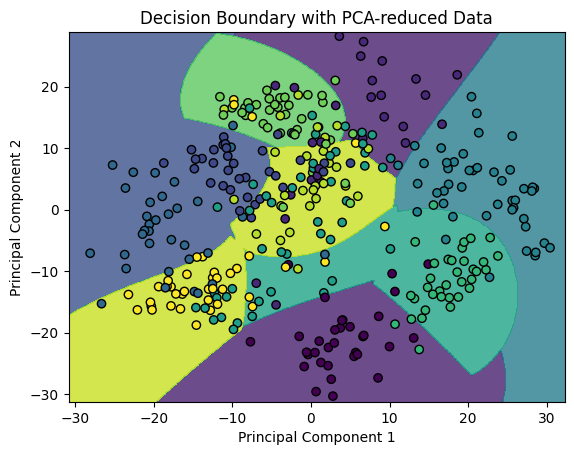

In [5]:
from sklearn.decomposition import PCA

# Perform PCA
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

# Train an SVM with Gaussian kernel on reduced data
rbf_svc_pca = svm.SVC(kernel='rbf', C=C, gamma='scale', random_state=42)
rbf_svc_pca.fit(X_train_pca, y_train)

# Visualize decision boundary
x_min, x_max = X_train_pca[:, 0].min() - 1, X_train_pca[:, 0].max() + 1
y_min, y_max = X_train_pca[:, 1].min() - 1, X_train_pca[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1),
                     np.arange(y_min, y_max, 0.1))

Z = rbf_svc_pca.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.contourf(xx, yy, Z, alpha=0.8)
plt.scatter(X_test_pca[:, 0], X_test_pca[:, 1], c=y_test, edgecolors='k')
plt.title("Decision Boundary with PCA-reduced Data")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()


### Step 7: Grid Search for Best Parameters


In [6]:
from sklearn.model_selection import GridSearchCV

# Define parameter grid
param_grid = {
    'kernel': ['linear', 'rbf', 'poly'],
    'C': [0.1, 1, 10],
    'gamma': ['scale', 'auto', 0.01, 0.1],
    'degree': [2, 3, 4]  # Only for polynomial kernel
}

# Perform grid search
svc = svm.SVC()
grid_search = GridSearchCV(svc, param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train, y_train)

# Print the best parameters and score
print(f"Best parameters: {grid_search.best_params_}")
print(f"Best cross-validation accuracy: {grid_search.best_score_:.2f}")


Best parameters: {'C': 10, 'degree': 2, 'gamma': 'scale', 'kernel': 'rbf'}
Best cross-validation accuracy: 0.99


### Step 8: Determine the Number of PCA Components for 97% Accuracy


In [7]:
# Check number of components for 97% accuracy
for n_components in range(1, X.shape[1] + 1):
    pca = PCA(n_components=n_components)
    X_train_pca = pca.fit_transform(X_train)
    X_test_pca = pca.transform(X_test)

    # Train and evaluate SVM
    rbf_svc_pca = svm.SVC(kernel='rbf', C=C, gamma='scale', random_state=42)
    rbf_svc_pca.fit(X_train_pca, y_train)
    score = rbf_svc_pca.score(X_test_pca, y_test)

    if score >= 0.97:
        print(f"97% accuracy achieved with {n_components} PCA components.")
        break


97% accuracy achieved with 9 PCA components.
